# Results plots from saved artifacts in this branch

This notebook uses only `ratings_train.npy`, `ratings_test.npy`, the saved ALS/GNN prediction arrays, and the two GNN checkpoints in `results/`. It does not retrain models or create missing experiment logs.

It reports the checkpoint metrics and ablations that were saved, plus test metrics computed directly from the saved predictions. There is no saved Blend prediction or blend weight in this branch. A blend means a weighted combination of model predictions, so it cannot be reproduced consistently without the original formula/weight or saved blend outputs.

The saved checkpoints include the selected hyperparameters, but not all search-trial results. They also do not include per-epoch validation/train cross-entropy histories. The plots therefore show the available CV/train/test RMSE summaries, not a hyperparameter grid or training curves.

In [2]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
while not (ROOT / "cf").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from cf.features import GenreData

RESULTS = ROOT / "results"
FIGURES = RESULTS / "plots"
FIGURES.mkdir(parents=True, exist_ok=True)

mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 220, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
    "legend.frameon": False,
})
COLORS = {
    "ALS+bias": "#1f77b4",
    "IMC-GAE · genre + year": "#ff7f0e",
    "IMC-GAE · genre + year + title": "#2ca02c",
}

def save_plot(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(FIGURES / f"{name}.png", bbox_inches="tight")
    plt.show()
    plt.close(fig)

print(f"Project: {ROOT}")
print(f"Figures will be saved to: {FIGURES}")

Matplotlib is building the font cache; this may take a moment.


Project: /Users/aaronaidoudi/Downloads/IMC-GAE-GROUP
Figures will be saved to: /Users/aaronaidoudi/Downloads/IMC-GAE-GROUP/results/plots


## Load the saved data, checkpoints, and predictions

The outer training split is `ratings_train.npy` (31,598 observed ratings here), and the holdout is `ratings_test.npy`. In `notebook_imc_gae`, a 10% split was used for one validation check, but the final saved checkpoints were retrained on the full outer training split. The training-count plots below therefore use all of `ratings_train.npy`, matching the saved final model's training graph.

In [3]:
train = np.load(ROOT / "data" / "ratings_train.npy")
test = np.load(ROOT / "data" / "ratings_test.npy")
if train.shape != test.shape:
    raise ValueError(f"Train/test shape mismatch: {train.shape} vs {test.shape}")

als_path = RESULTS / "als_predictions.npy"
if not als_path.exists():
    from cf.models.als import ALSRecommender
    als = ALSRecommender(
        n_factors=20, lam=10.0, lam_bias=5.0, n_iters=15, random_state=0,
    ).fit(train)
    np.save(als_path, als.predict_all())

prediction_tables = {"ALS+bias": np.load(als_path)}
checkpoints = sorted(RESULTS.glob(
    "imc_gae_*_genre_normalized_year_title_shared_feature_projection_*.pt"
))
checkpoint_data = {}
for checkpoint_path in checkpoints:
    checkpoint = __import__("torch").load(checkpoint_path, map_location="cpu", weights_only=False)
    features = checkpoint.get("feature_names", [])
    if "title" in features:
        label = "IMC-GAE · genre + year + title"
    else:
        label = "IMC-GAE · genre + year"
    prediction_path = RESULTS / checkpoint_path.name.replace(
        "imc_gae_", "imc_gae_predictions_", 1
    ).replace(".pt", ".npy")
    if not prediction_path.exists():
        print(f"Skipping {checkpoint_path.name}: prediction file not found")
        continue
    if label in prediction_tables:
        raise ValueError(f"More than one checkpoint maps to {label}; select runs explicitly")
    prediction_tables[label] = np.load(prediction_path)
    checkpoint_data[label] = checkpoint

if len(prediction_tables) < 3:
    raise FileNotFoundError("Expected ALS and both saved normalized-year IMC-GAE predictions")
for name, pred in prediction_tables.items():
    if pred.shape != train.shape or not np.isfinite(pred).all():
        raise ValueError(f"Invalid prediction table for {name}: {pred.shape}")

observed = np.isfinite(test)
users, items = np.where(observed)
y_test = test[observed].astype(float)
pred_test = {name: pred[observed].astype(float) for name, pred in prediction_tables.items()}
print(f"Train ratings: {np.isfinite(train).sum():,}; test ratings: {len(y_test):,}")
print("Loaded models:", ", ".join(prediction_tables))

Train ratings: 31,598; test ratings: 31,598
Loaded models: ALS+bias, IMC-GAE · genre + year, IMC-GAE · genre + year + title


## Shared metric helpers

Bootstrap intervals resample held-out ratings. Model differences use paired resamples, so each method is compared on the same sampled ratings.

In [4]:
def rmse(pred, truth):
    return float(np.sqrt(np.mean((pred - truth) ** 2)))

def mae(pred, truth):
    return float(np.mean(np.abs(pred - truth)))

def bootstrap_ci(pred, truth, metric, n_boot=400, seed=0):
    rng = np.random.default_rng(seed)
    n = len(truth)
    values = np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, n, n)
        values[b] = metric(pred[idx], truth[idx])
    return metric(pred, truth), np.percentile(values, [2.5, 97.5])

def paired_delta_ci(pred, baseline, truth, metric=rmse, n_boot=300, seed=0):
    rng = np.random.default_rng(seed)
    n = len(truth)
    values = np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, n, n)
        values[b] = metric(pred[idx], truth[idx]) - metric(baseline[idx], truth[idx])
    point = metric(pred, truth) - metric(baseline, truth)
    return point, np.percentile(values, [2.5, 97.5])

## 1. What is in the outer train/test split?

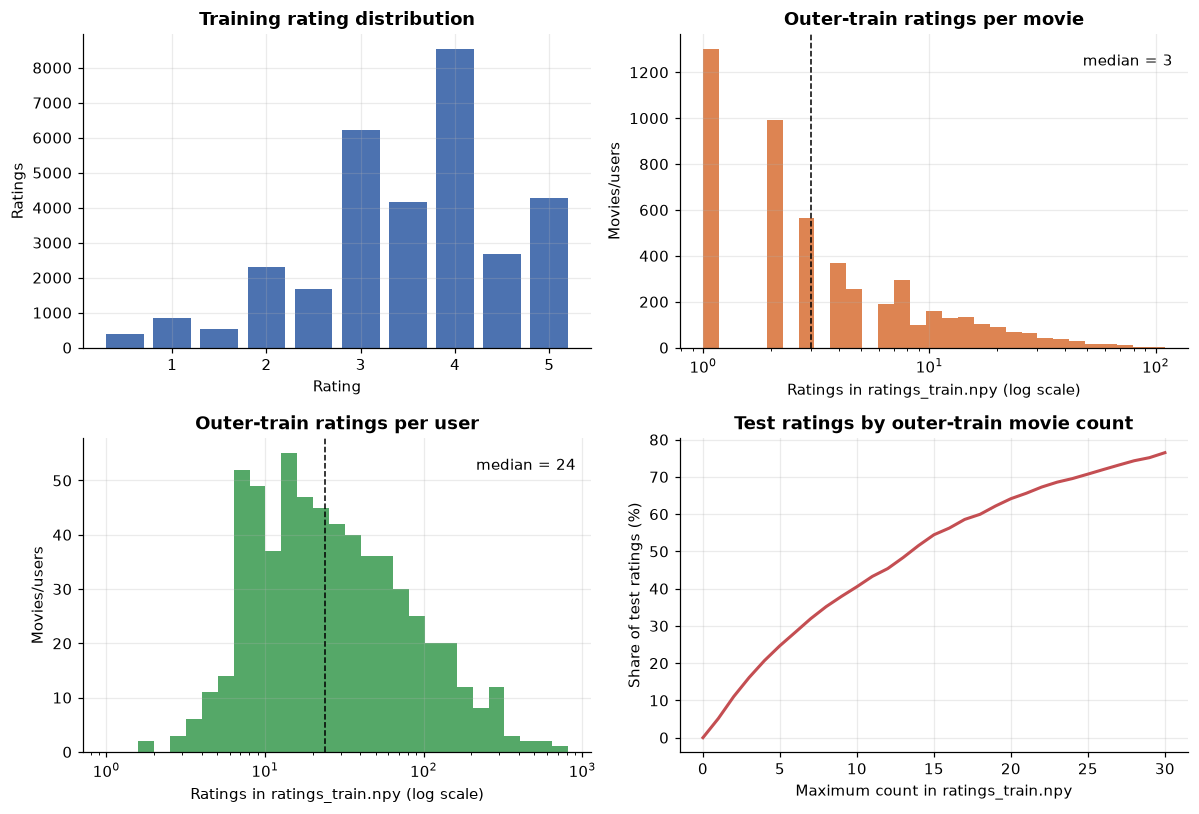

In [5]:
train_item_count = np.isfinite(train).sum(axis=0)
train_user_count = np.isfinite(train).sum(axis=1)

fig, ax = plt.subplots(2, 2, figsize=(11, 7.5))
levels, counts = np.unique(train[np.isfinite(train)], return_counts=True)
ax[0, 0].bar(levels, counts, width=0.4, color="#4c72b0")
ax[0, 0].set(title="Training rating distribution", xlabel="Rating", ylabel="Ratings")

for a, deg, title, color in [
    (ax[0, 1], train_item_count, "Outer-train ratings per movie", "#dd8452"),
    (ax[1, 0], train_user_count, "Outer-train ratings per user", "#55a868"),
]:
    a.hist(deg[deg > 0], bins=np.logspace(0, np.log10(deg.max() + 1), 30), color=color)
    a.set_xscale("log")
    a.axvline(np.median(deg), color="black", linestyle="--", linewidth=1)
    a.set(title=title, xlabel="Ratings in ratings_train.npy (log scale)", ylabel="Movies/users")
    a.text(0.97, 0.9, f"median = {np.median(deg):.0f}", transform=a.transAxes, ha="right")

ks = np.arange(0, 31)
ax[1, 1].plot(ks, [100 * np.mean(train_item_count[items] <= k) for k in ks], color="#c44e52", linewidth=2)
ax[1, 1].set(title="Test ratings by outer-train movie count", xlabel="Maximum count in ratings_train.npy", ylabel="Share of test ratings (%)")
save_plot(fig, "fig1_data_overview")

## 2. Overall test performance

Lower RMSE and MAE are better. The horizontal bars show 95% bootstrap intervals across test ratings.

,test_RMSE,RMSE_CI_low,RMSE_CI_high,test_MAE,MAE_CI_low,MAE_CI_high
model,,,,,,
ALS+bias,0.8720,0.8646,0.8805,0.6714,0.6657,0.6782
IMC-GAE · genre + year,0.8773,0.8695,0.8860,0.6702,0.6643,0.6767
IMC-GAE · genre + year + title,0.8837,0.8759,0.8923,0.6763,0.6702,0.6826


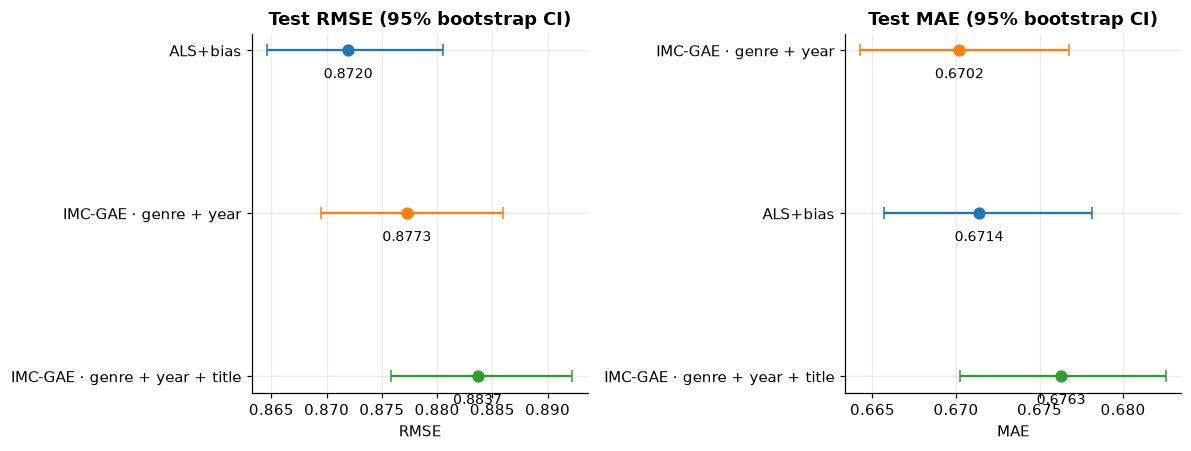

In [6]:
overall_rows = []
metric_cis = {"RMSE": {}, "MAE": {}}
for i, (name, pred) in enumerate(pred_test.items()):
    r, r_ci = bootstrap_ci(pred, y_test, rmse, seed=10)
    a, a_ci = bootstrap_ci(pred, y_test, mae, seed=10)
    metric_cis["RMSE"][name] = (r, r_ci)
    metric_cis["MAE"][name] = (a, a_ci)
    overall_rows.append({"model": name, "test_RMSE": r, "RMSE_CI_low": r_ci[0], "RMSE_CI_high": r_ci[1],
                         "test_MAE": a, "MAE_CI_low": a_ci[0], "MAE_CI_high": a_ci[1]})
overall_metrics = pd.DataFrame(overall_rows).sort_values("test_RMSE")
display(overall_metrics.set_index("model").round(4))

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for panel, metric_name in zip(ax, ("RMSE", "MAE")):
    ranked = sorted(metric_cis[metric_name].items(), key=lambda x: x[1][0])
    for row, (name, (point, ci)) in enumerate(ranked):
        panel.errorbar(point, row, xerr=[[point-ci[0]], [ci[1]-point]], fmt="o", capsize=4,
                       color=COLORS[name], markersize=7)
        panel.text(point, row + 0.17, f"{point:.4f}", ha="center", fontsize=9)
    panel.set_yticks(range(len(ranked)))
    panel.set_yticklabels([x[0] for x in ranked])
    panel.invert_yaxis()
    panel.set(title=f"Test {metric_name} (95% bootstrap CI)", xlabel=metric_name)
save_plot(fig, "fig2_overall_test_metrics")

## 3. Performance by movie popularity

Movie groups use counts from the full outer training matrix, `ratings_train.npy`. The right panel is the paired test RMSE difference from ALS+bias for each saved GNN prediction; negative values favor that GNN. There is no Blend prediction in the saved results.

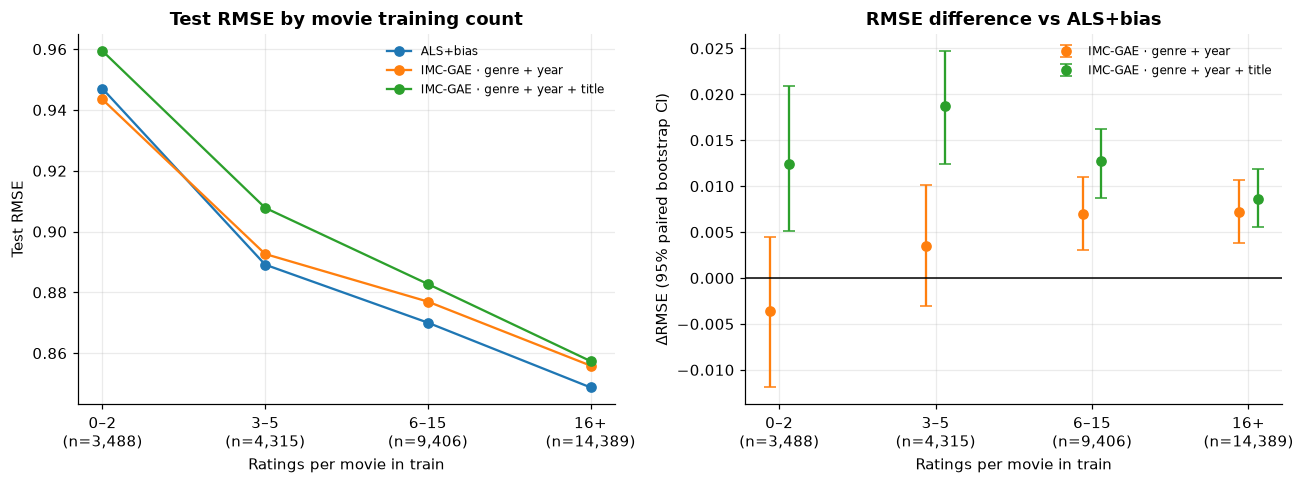

In [7]:
item_group_names = ["0–2", "3–5", "6–15", "16+"]
item_group_id = np.digitize(train_item_count[items], [3, 6, 16])
item_groups = [(label, item_group_id == i) for i, label in enumerate(item_group_names)]
item_group_sizes = [int(mask.sum()) for _, mask in item_groups]

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for name, pred in pred_test.items():
    ax[0].plot(range(len(item_groups)), [rmse(pred[m], y_test[m]) for _, m in item_groups], "o-",
               color=COLORS[name], label=name)
ax[0].set_xticks(range(len(item_groups)))
ax[0].set_xticklabels([f"{name}\n(n={n:,})" for (name, _), n in zip(item_groups, item_group_sizes)])
ax[0].set(title="Test RMSE by movie training count", xlabel="Ratings per movie in train", ylabel="Test RMSE")
ax[0].legend(fontsize=8)

for offset, name in zip((-0.06, 0.06), [n for n in pred_test if n != "ALS+bias"]):
    points, lows, highs = [], [], []
    for seed, (_, mask) in enumerate(item_groups):
        point, ci = paired_delta_ci(pred_test[name][mask], pred_test["ALS+bias"][mask], y_test[mask], seed=seed)
        points.append(point); lows.append(ci[0]); highs.append(ci[1])
    points, lows, highs = map(np.asarray, (points, lows, highs))
    ax[1].errorbar(np.arange(len(item_groups)) + offset, points,
                   yerr=[points-lows, highs-points], fmt="o", capsize=4,
                   color=COLORS[name], label=name)
ax[1].axhline(0, color="black", linewidth=1)
ax[1].set_xticks(range(len(item_groups)))
ax[1].set_xticklabels([f"{name}\n(n={n:,})" for (name, _), n in zip(item_groups, item_group_sizes)])
ax[1].set(title="RMSE difference vs ALS+bias", xlabel="Ratings per movie in train", ylabel="ΔRMSE (95% paired bootstrap CI)")
ax[1].legend(fontsize=8)
save_plot(fig, "fig3_test_error_by_movie_count")

## 4. Performance by user activity

User activity is counted from the full outer training matrix, `ratings_train.npy`, because the saved checkpoints were fit on that matrix.

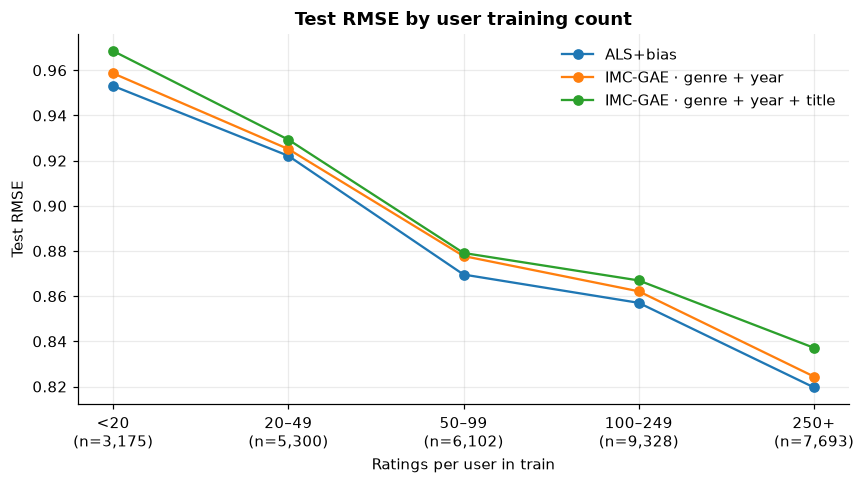

In [8]:
user_group_names = ["<20", "20–49", "50–99", "100–249", "250+"]
user_group_id = np.digitize(train_user_count[users], [20, 50, 100, 250])
user_groups = [(label, user_group_id == i) for i, label in enumerate(user_group_names)]
fig, ax = plt.subplots(figsize=(8, 4.5))
for name, pred in pred_test.items():
    ax.plot(range(len(user_groups)), [rmse(pred[m], y_test[m]) for _, m in user_groups], "o-",
            color=COLORS[name], label=name)
ax.set_xticks(range(len(user_groups)))
ax.set_xticklabels([f"{label}\n(n={mask.sum():,})" for label, mask in user_groups])
ax.set(title="Test RMSE by user training count", xlabel="Ratings per user in train", ylabel="Test RMSE")
ax.legend()
save_plot(fig, "fig4_test_error_by_user_count")

## 5. Error by true rating

The left panel measures absolute error within each true rating. The right panel shows signed error (prediction minus truth); positive values mean overprediction.

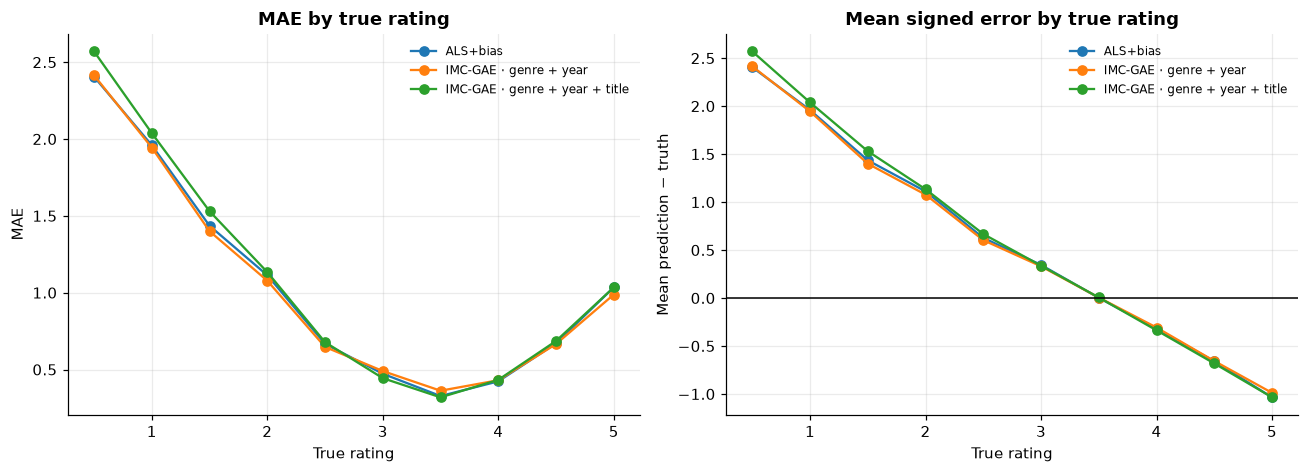

In [9]:
rating_levels = np.sort(np.unique(y_test))
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
for name, pred in pred_test.items():
    masks = [y_test == level for level in rating_levels]
    ax[0].plot(rating_levels, [np.mean(np.abs(pred[m] - y_test[m])) for m in masks], "o-",
               color=COLORS[name], label=name)
    ax[1].plot(rating_levels, [np.mean(pred[m] - y_test[m]) for m in masks], "o-",
               color=COLORS[name], label=name)
ax[0].set(title="MAE by true rating", xlabel="True rating", ylabel="MAE")
ax[0].legend(fontsize=8)
ax[1].axhline(0, color="black", linewidth=1)
ax[1].set(title="Mean signed error by true rating", xlabel="True rating", ylabel="Mean prediction − truth")
ax[1].legend(fontsize=8)
save_plot(fig, "fig5_error_by_true_rating")

## 6. Checkpoint metrics and selected settings

These values come directly from each saved checkpoint. `cv_rmse` is the saved three-fold cross-validation summary; the checkpoint does not contain predictions for one separate validation split.

,cv_rmse,train_rmse,test_rmse
model,,,
IMC-GAE · genre + year,0.8843,0.7870,0.8773
IMC-GAE · genre + year + title,0.8830,0.8162,0.8837


Selected settings saved in the checkpoints (not a grid of all trials):


,starting_dim,d_shared,d_role,d_genre_year,d_title,d_personal,d_feat,n_layers,weight_decay,learning_rate
model,,,,,,,,,,
IMC-GAE · genre + year,100,16,16,4,NaN,64,4,3,0.00732,0.00290
IMC-GAE · genre + year + title,64,16,8,4,4.0,32,4,3,0.00515,0.00383


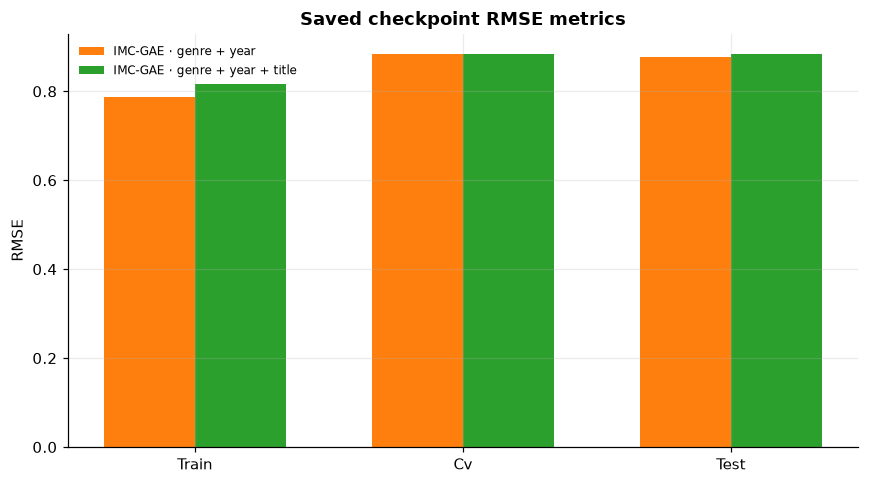

In [10]:
checkpoint_rows = []
config_rows = []
for name, checkpoint in checkpoint_data.items():
    checkpoint_rows.append({"model": name, **checkpoint.get("metrics", {})})
    params = checkpoint.get("best_params", {})
    description = checkpoint.get("description", {})
    start = description.get("starting_vector", {})
    config_rows.append({
        "model": name,
        "starting_dim": description.get("dim"),
        "d_shared": params.get("d_shared"),
        "d_role": params.get("d_role"),
        "d_genre_year": start.get("genre_year"),
        "d_title": start.get("title"),
        "d_personal": params.get("d_personal"),
        "d_feat": params.get("d_feat"),
        "n_layers": params.get("n_layers"),
        "weight_decay": params.get("weight_decay"),
        "learning_rate": params.get("lr"),
    })

checkpoint_metrics = pd.DataFrame(checkpoint_rows).set_index("model")
display(checkpoint_metrics.round(4))
print("Selected settings saved in the checkpoints (not a grid of all trials):")
display(pd.DataFrame(config_rows).set_index("model").round(5))

metric_cols = [column for column in ("train_rmse", "cv_rmse", "test_rmse") if column in checkpoint_metrics]
if metric_cols:
    fig, ax = plt.subplots(figsize=(8, 4.5))
    x = np.arange(len(metric_cols))
    width = 0.34
    for j, (name, row) in enumerate(checkpoint_metrics.iterrows()):
        values = [row.get(col, np.nan) for col in metric_cols]
        ax.bar(x + (j - (len(checkpoint_metrics)-1)/2) * width, values, width,
               color=COLORS[name], label=name)
    ax.set_xticks(x)
    ax.set_xticklabels([col.replace("_rmse", "").replace("_", " ").title() for col in metric_cols])
    ax.set(title="Saved checkpoint RMSE metrics", ylabel="RMSE")
    ax.legend(fontsize=8)
    save_plot(fig, "fig6_checkpoint_metrics")

## 7. Saved component ablations

These test RMSE values are stored in the checkpoints. Each ablation zeros one whole saved component and evaluates the checkpoint; it does not retrain the model. `shared` is the common node vector, `role` distinguishes user/item nodes, and `personal` is the per-node/per-rating vector. The feature ablation is one combined `genre_year` block (genre columns plus normalized release year); title is a separate block in the title model. The saved results do not contain separate genre-by-genre or year-only ablation scores.

model,IMC-GAE · genre + year,IMC-GAE · genre + year + title
component,,
full model,0.0000,0.0000
without combined genre + year features,0.0033,0.0041
without personal vectors,0.1285,0.1318
without shared/common vector,0.4638,0.0774
without title features,NaN,0.0005
without user/item role vectors,0.2011,0.0623


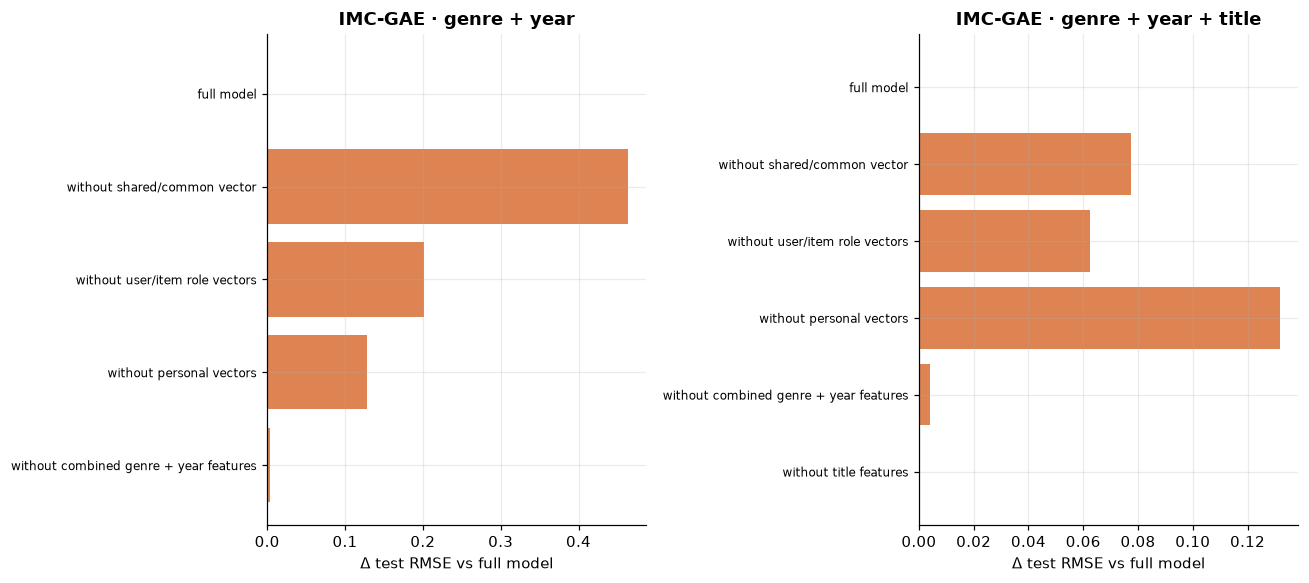

In [11]:
ablation_labels = {
    "full": "full model",
    "no_shared": "without shared/common vector",
    "no_role": "without user/item role vectors",
    "no_personal": "without personal vectors",
    "no_genre_year": "without combined genre + year features",
    "no_title": "without title features",
}
ablations = {name: checkpoint.get("ablation", {}).get("test", {})
             for name, checkpoint in checkpoint_data.items()}
ablations = {name: values for name, values in ablations.items() if values}
if ablations:
    ablation_rows = []
    for name, values in ablations.items():
        full_rmse = values["full"]
        for key, value in values.items():
            ablation_rows.append({"model": name, "component": ablation_labels.get(key, key),
                                 "test_RMSE": value, "delta_from_full": value - full_rmse})
    ablation_table = pd.DataFrame(ablation_rows)
    display(ablation_table.pivot(index="component", columns="model", values="delta_from_full").round(4))

    fig, axes = plt.subplots(1, len(ablations), figsize=(6 * len(ablations), 5.4), squeeze=False)
    for axis, (name, values) in zip(axes[0], ablations.items()):
        keys = list(values)
        deltas = [values[key] - values["full"] for key in keys]
        colors = ["#4c72b0" if key == "full" else "#dd8452" for key in keys]
        axis.barh(np.arange(len(keys)), deltas, color=colors)
        axis.axvline(0, color="black", linewidth=1)
        axis.set_yticks(np.arange(len(keys)))
        axis.set_yticklabels([ablation_labels.get(key, key) for key in keys], fontsize=8)
        axis.invert_yaxis()
        axis.set(title=name, xlabel="Δ test RMSE vs full model")
    save_plot(fig, "fig7_checkpoint_feature_ablations")
else:
    print("No feature ablation metrics are stored in these checkpoints.")

## 8. Accuracy versus RMSE from saved expected-rating predictions

This is not the same as the original notebook's argmax/confidence-threshold blend plot. The saved `.npy` files contain continuous expected ratings, but not class probabilities/logits, and the results do not contain a Blend prediction. Here, predictions are rounded to the nearest half-star using the dataset's rating scale; we compare exact-match accuracy with RMSE for those rounded outputs. The calibration panel uses the original continuous predictions.

,continuous_RMSE,rounded_RMSE,rounded_exact_accuracy
model,,,
ALS+bias,0.8720,0.8843,0.2470
IMC-GAE · genre + year,0.8773,0.8881,0.2540
IMC-GAE · genre + year + title,0.8837,0.8942,0.2506


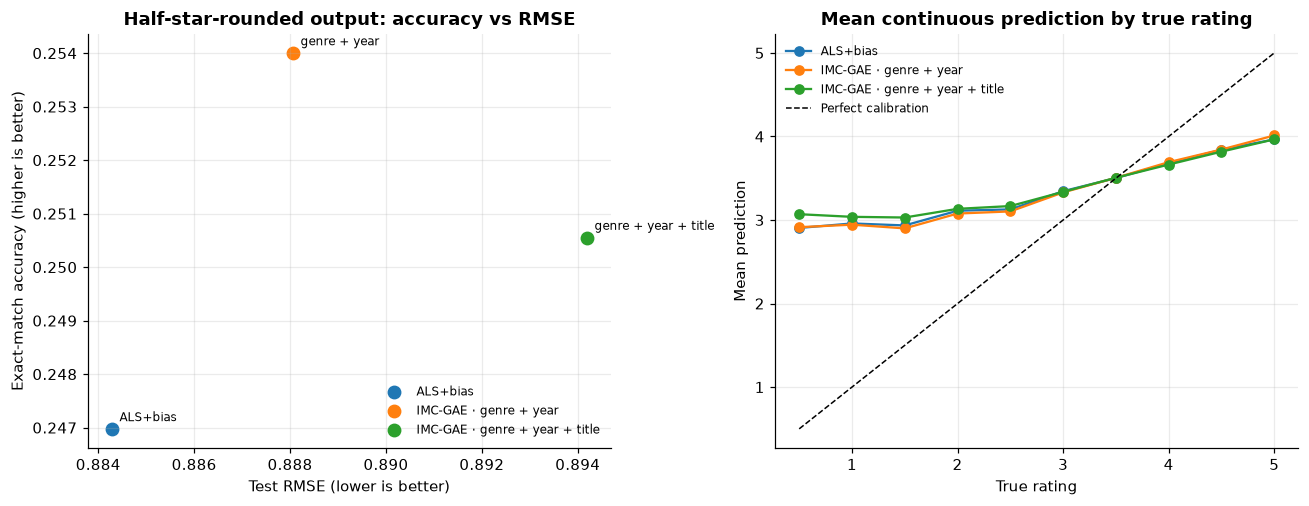

Saved 9 PNGs and 9 PDFs in /Users/aaronaidoudi/Downloads/IMC-GAE-GROUP/results/plots


In [12]:
def snap_half_star(pred):
    return np.clip(np.round(pred * 2) / 2, 0.5, 5.0)

def exact_accuracy(pred):
    return float(np.mean(pred == y_test))

rounding_rows = []
rounded_predictions = {}
for name, pred in pred_test.items():
    rounded = snap_half_star(pred)
    rounded_predictions[name] = rounded
    rounding_rows.append({
        "model": name,
        "continuous_RMSE": rmse(pred, y_test),
        "rounded_RMSE": rmse(rounded, y_test),
        "rounded_exact_accuracy": exact_accuracy(rounded),
    })
display(pd.DataFrame(rounding_rows).set_index("model").round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.7))
for name, rounded in rounded_predictions.items():
    point = (rmse(rounded, y_test), exact_accuracy(rounded))
    ax[0].scatter(*point, color=COLORS[name], s=65, label=name)
    ax[0].annotate(name.replace("IMC-GAE · ", ""), point,
                   textcoords="offset points", xytext=(5, 5), fontsize=8)

for name, pred in pred_test.items():
    means = [pred[y_test == level].mean() for level in rating_levels]
    ax[1].plot(rating_levels, means, "o-", color=COLORS[name], label=name)
ax[1].plot([0.5, 5], [0.5, 5], "k--", linewidth=1, label="Perfect calibration")
ax[0].set(title="Half-star-rounded output: accuracy vs RMSE", xlabel="Test RMSE (lower is better)", ylabel="Exact-match accuracy (higher is better)")
ax[0].legend(fontsize=8)
ax[1].set(title="Mean continuous prediction by true rating", xlabel="True rating", ylabel="Mean prediction")
ax[1].legend(fontsize=8)
save_plot(fig, "fig8_accuracy_rmse_calibration")

print(f"Saved {len(list(FIGURES.glob('*.png')))} PNGs and {len(list(FIGURES.glob('*.pdf')))} PDFs in {FIGURES}")

## 9. Refit the saved configurations to recover CV learning curves

The checkpoints retain their selected parameters and CV protocol, but not per-epoch histories. This cell replays only those saved configurations from a fresh initialization, using the checkpoint's recorded fold count, seed, evaluation interval, patience, and maximum epochs. It does not rerun the hyperparameter search or alter the saved checkpoints. The replay's fold-best RMSE is shown beside the checkpoint CV RMSE so any reproducibility difference is visible.

/Users/aaronaidoudi/Downloads/IMC-GAE-GROUP/cf/graph.py:40: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:855.)
  adj = torch.sparse_coo_tensor(


model,IMC-GAE · genre + year,IMC-GAE · genre + year + title
fold,,
1,0.8958,0.8973
2,0.8875,0.8813
3,0.8696,0.8705


,replay_cv_rmse,saved_cv_rmse,difference
model,,,
IMC-GAE · genre + year,0.88432,0.88432,0.0
IMC-GAE · genre + year + title,0.88302,0.88302,0.0


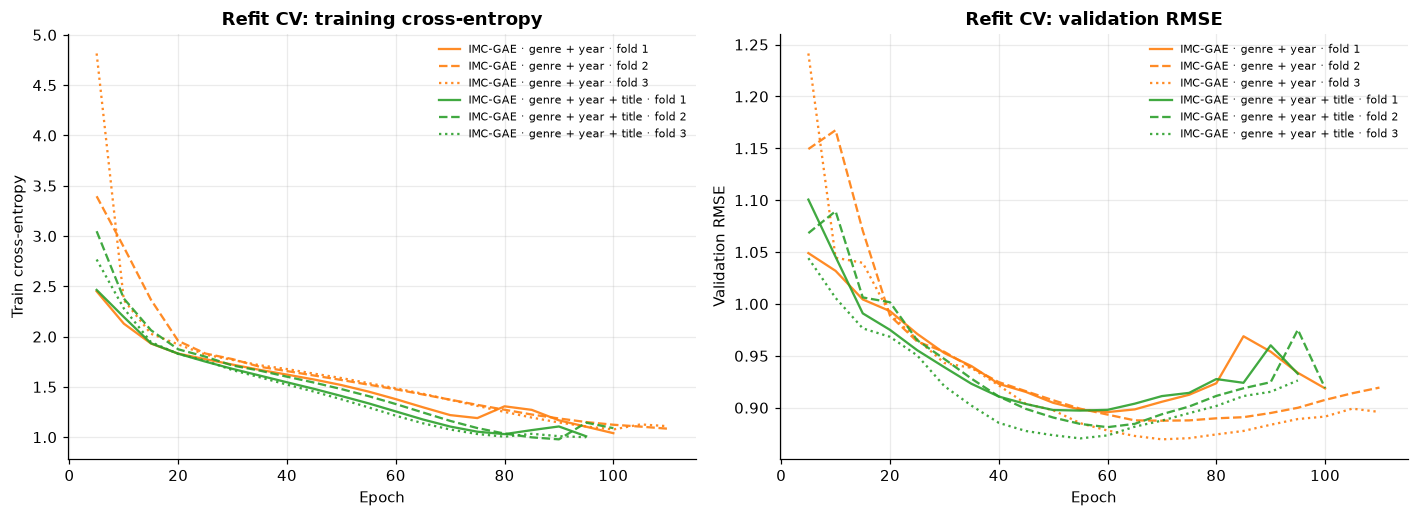

In [13]:
import torch
from cf.data import RatingData
from cf.graph import RatingGraphs
from cf.models.imc_gae import IMCGAE
from cf.trainer import Trainer

cv_data = RatingData(train)
replay_histories = {}
replay_rows = []

for model_name, checkpoint in checkpoint_data.items():
    params = checkpoint["best_params"]
    protocol = checkpoint["search"]
    variant = checkpoint["variant"]
    if variant.get("side", False):
        raise NotImplementedError("This replay cell currently supports checkpoints without side terms")

    n_splits = int(protocol["n_splits"])
    rng = np.random.default_rng(int(protocol["seed"]))
    candidate_folds = np.array_split(rng.permutation(len(cv_data.ratings)), n_splits)
    model_folds = []

    for fold_number, candidate_val_idx in enumerate(candidate_folds):
        train_mask = np.ones(len(cv_data.ratings), dtype=bool)
        train_mask[candidate_val_idx] = False
        train_user_count = np.bincount(cv_data.users[train_mask], minlength=cv_data.n_users)
        train_item_count = np.bincount(cv_data.items[train_mask], minlength=cv_data.n_items)
        for idx in candidate_val_idx:
            user, item = cv_data.users[idx], cv_data.items[idx]
            if train_user_count[user] == 0 or train_item_count[item] == 0:
                train_mask[idx] = True
                train_user_count[user] += 1
                train_item_count[item] += 1

        train_idx = np.flatnonzero(train_mask)
        val_idx = np.flatnonzero(~train_mask)
        fit = (cv_data.users[train_idx], cv_data.items[train_idx],
               cv_data.level_idx[train_idx], cv_data.ratings[train_idx])
        val = (cv_data.users[val_idx], cv_data.items[val_idx],
               cv_data.level_idx[val_idx], cv_data.ratings[val_idx])

        # Match the seed handling used by Trainer.cross_validate.
        fold_seed = int(protocol["seed"]) + fold_number
        torch.manual_seed(fold_seed)
        np.random.seed(fold_seed)
        graphs = RatingGraphs(fit[0], fit[1], fit[2], cv_data.n_users,
                              cv_data.n_items, cv_data.T)
        state = checkpoint["model_state_dict"]
        features = {
            feature_name: state[f"embedding.features_{k}"].detach().cpu().numpy()
            for k, feature_name in enumerate(checkpoint.get("feature_names", []))
        }
        model = IMCGAE(
            cv_data.n_users, cv_data.n_items, cv_data.T,
            d_shared=params["d_shared"], d_role=params["d_role"],
            d_personal=params["d_personal"], out_dim=params["out_dim"],
            n_layers=params["n_layers"], p0=params["p0"], theta=params["theta"],
            side=None, use_bias=variant.get("use_bias", False),
            layer_weights=variant.get("layer_weights", False), features=features,
            d_feat=params.get("d_feat", 8),
            share_feature_weights=variant.get("share_feature_weights", False),
        )
        trainer = Trainer(
            model, graphs, cv_data.levels,
            lr=params["lr"], lam=params["lam"],
            weight_decay=params["weight_decay"], optimizer=params["optimizer"],
            epochs=int(protocol["max_epochs"]),
            eval_every=int(protocol["eval_every"]),
            patience=int(protocol["patience"]), verbose=False,
        )
        history = trainer.fit(fit, val)
        model_folds.append(history)
        best = min(history, key=lambda row: row["val_rmse"])
        replay_rows.append({
            "model": model_name, "fold": fold_number + 1,
            "best_epoch": best["epoch"], "best_val_RMSE": best["val_rmse"],
            "train_RMSE_at_best": best["train_rmse"],
        })

    replay_histories[model_name] = model_folds

replay_fold_table = pd.DataFrame(replay_rows)
display(replay_fold_table.pivot(index="fold", columns="model", values="best_val_RMSE").round(4))
replay_summary = replay_fold_table.groupby("model")["best_val_RMSE"].mean().rename("replay_cv_rmse").to_frame()
replay_summary["saved_cv_rmse"] = pd.Series({name: checkpoint["metrics"]["cv_rmse"]
                                               for name, checkpoint in checkpoint_data.items()})
replay_summary["difference"] = replay_summary["replay_cv_rmse"] - replay_summary["saved_cv_rmse"]
display(replay_summary.round(5))

fold_styles = ["-", "--", ":"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
for model_name, folds in replay_histories.items():
    for fold_number, history in enumerate(folds):
        epochs = [row["epoch"] for row in history]
        style = fold_styles[fold_number % len(fold_styles)]
        label = f"{model_name} · fold {fold_number + 1}"
        ax[0].plot(epochs, [row["train_ce"] for row in history], linestyle=style,
                   color=COLORS[model_name], alpha=0.9, label=label)
        ax[1].plot(epochs, [row["val_rmse"] for row in history], linestyle=style,
                   color=COLORS[model_name], alpha=0.9, label=label)
ax[0].set(title="Refit CV: training cross-entropy", xlabel="Epoch", ylabel="Train cross-entropy")
ax[1].set(title="Refit CV: validation RMSE", xlabel="Epoch", ylabel="Validation RMSE")
for axis in ax:
    axis.legend(fontsize=7)
save_plot(fig, "fig9_refit_cv_training_dynamics")

In [14]:
import io, contextlib

def show(title, df):
    print(f"\n### {title}")
    print(df.round(4).to_string())

def build_summary():
    models = list(pred_test)
    item_cnt = np.isfinite(train).sum(axis=0)     # ratings per movie in outer train
    user_cnt = np.isfinite(train).sum(axis=1)     # ratings per user in outer train
    print(f"train ratings: {int(np.isfinite(train).sum())} | test ratings: {len(y_test)} | shape (users, items): {train.shape}")

    # Fig 1
    lv, ct = np.unique(train[np.isfinite(train)], return_counts=True)
    show("Fig1 rating distribution (train)", pd.DataFrame({"count": ct}, index=pd.Index(lv, name="rating")))
    q = [0.1, 0.25, 0.5, 0.75, 0.9, 0.99]
    show("Fig1 ratings per movie / per user in train (quantiles)",
         pd.DataFrame({"movies": np.quantile(item_cnt, q), "users": np.quantile(user_cnt, q)},
                      index=[f"q{int(100 * x)}" for x in q]))
    print(f"movies with 0 train ratings: {int((item_cnt == 0).sum())} | mean per movie: {item_cnt.mean():.2f} | mean per user: {user_cnt.mean():.1f}")
    ks = [0, 1, 2, 3, 5, 10, 20, 30]
    show("Fig1 share of test ratings on movies with <= k train ratings (%)",
         pd.DataFrame({"share_pct": [100 * np.mean(item_cnt[items] <= k) for k in ks]}, index=pd.Index(ks, name="k")))

    # Fig 2
    show("Fig2 overall test metrics (95% bootstrap CI)", overall_metrics.set_index("model"))

    # Fig 3: error by movie popularity
    grp = np.digitize(item_cnt[items], [3, 6, 16])
    rows = []
    for g, nm in enumerate(["0-2", "3-5", "6-15", "16+"]):
        m = grp == g
        row = {"group": nm, "n": int(m.sum())}
        for n_ in models:
            row[f"RMSE {n_}"] = rmse(pred_test[n_][m], y_test[m])
        for n_ in models:
            if n_ != "ALS+bias":
                d, ci = paired_delta_ci(pred_test[n_][m], pred_test["ALS+bias"][m], y_test[m], seed=g)
                row[f"dRMSE vs ALS, {n_}"] = f"{d:+.4f} [{ci[0]:+.4f}, {ci[1]:+.4f}]"
        rows.append(row)
    show("Fig3 test RMSE by movie training count (+ paired delta vs ALS, 95% CI)", pd.DataFrame(rows).set_index("group"))

    # Fig 4: error by user activity
    grp = np.digitize(user_cnt[users], [20, 50, 100, 250])
    rows = []
    for g, nm in enumerate(["<20", "20-49", "50-99", "100-249", "250+"]):
        m = grp == g
        row = {"group": nm, "n": int(m.sum())}
        for n_ in models:
            row[f"RMSE {n_}"] = rmse(pred_test[n_][m], y_test[m])
        rows.append(row)
    show("Fig4 test RMSE by user training count", pd.DataFrame(rows).set_index("group"))

    # Fig 5: error by true rating
    rows = []
    for lvl in rating_levels:
        m = y_test == lvl
        row = {"rating": lvl, "n": int(m.sum())}
        for n_ in models:
            row[f"MAE {n_}"] = mae(pred_test[n_][m], y_test[m])
            row[f"signed {n_}"] = float(np.mean(pred_test[n_][m] - y_test[m]))
        rows.append(row)
    show("Fig5 MAE and mean signed error by true rating", pd.DataFrame(rows).set_index("rating"))

    # Fig 6: checkpoints
    show("Fig6 checkpoint metrics", checkpoint_metrics)
    show("Fig6 selected settings", pd.DataFrame(config_rows).set_index("model"))
    for n_, ck in checkpoint_data.items():
        print(f"\n{n_}: best_params={ck.get('best_params')} | best_epoch={ck.get('best_epoch')} | search={ck.get('search')}")

    # Fig 7: ablations
    if ablations:
        show("Fig7 ablation, test RMSE", pd.DataFrame(ablations))
        show("Fig7 ablation, delta vs full", pd.DataFrame({n_: {k: v - vals["full"] for k, v in vals.items()}
                                                           for n_, vals in ablations.items()}))

    # Fig 8: rounding and calibration
    show("Fig8 half-star rounding", pd.DataFrame(rounding_rows).set_index("model"))
    show("Fig8 mean continuous prediction by true rating",
         pd.DataFrame({n_: [pred_test[n_][y_test == l].mean() for l in rating_levels] for n_ in models},
                      index=pd.Index(rating_levels, name="true rating")))

    # Fig 9: replayed CV
    if "replay_fold_table" in globals():
        show("Fig9 replay: best epoch / val RMSE per fold", replay_fold_table.set_index(["model", "fold"]))
        show("Fig9 replay vs saved CV RMSE", replay_summary)
        for n_, folds in replay_histories.items():
            for k, h in enumerate(folds, 1):
                d = pd.DataFrame(h)[["epoch", "train_ce", "val_rmse"]]
                keep = d[(d.epoch % 20 == 0) | (d.val_rmse == d.val_rmse.min()) | (d.epoch == d.epoch.max())]
                show(f"Fig9 history: {n_}, fold {k}", keep.set_index("epoch"))

buf = io.StringIO()
with contextlib.redirect_stdout(buf):
    build_summary()
summary = buf.getvalue()
(RESULTS / "results_summary.txt").write_text(summary)
print(summary)

train ratings: 31598 | test ratings: 31598 | shape (users, items): (610, 4980)

### Fig1 rating distribution (train)
        count
rating       
0.5       382
1.0       853
1.5       526
2.0      2308
2.5      1665
3.0      6231
3.5      4153
4.0      8532
4.5      2675
5.0      4273

### Fig1 ratings per movie / per user in train (quantiles)
     movies   users
q10     1.0    7.00
q25     1.0   11.25
q50     3.0   24.00
q75     7.0   57.00
q90    15.0  124.10
q99    48.0  377.74
movies with 0 train ratings: 0 | mean per movie: 6.34 | mean per user: 51.8

### Fig1 share of test ratings on movies with <= k train ratings (%)
    share_pct
k            
0      0.0000
1      5.1459
2     11.0387
3     16.1498
5     24.6946
10    40.5216
20    64.1528
30    76.5017

### Fig2 overall test metrics (95% bootstrap CI)
                                test_RMSE  RMSE_CI_low  RMSE_CI_high  test_MAE  MAE_CI_low  MAE_CI_high
model                                                                      

In [15]:
import torch
from cf.data import RatingData
from cf.graph import RatingGraphs
from cf.models.imc_gae import IMCGAE
from cf.trainer import Trainer
from cf.models.als import ALSRecommender

rd = RatingData(train)
levels_t = torch.as_tensor(rd.levels, dtype=torch.float32)
ck = checkpoint_data["IMC-GAE · genre + year + title"]
P, V = ck["best_params"], ck["variant"]
feats = {n: ck["model_state_dict"][f"embedding.features_{k}"].numpy() for k, n in enumerate(ck["feature_names"])}

def build():
    return IMCGAE(rd.n_users, rd.n_items, rd.T, d_shared=P["d_shared"], d_role=P["d_role"],
                  d_personal=P["d_personal"], out_dim=P["out_dim"], n_layers=P["n_layers"],
                  p0=P["p0"], theta=P["theta"], side=None, use_bias=V.get("use_bias", False),
                  layer_weights=V.get("layer_weights", False), features=feats,
                  d_feat=P.get("d_feat", 8), share_feature_weights=V.get("share_feature_weights", False))

item_cnt_full = np.isfinite(train).sum(axis=0)
low = item_cnt_full[items] <= 5                    # movies with <= 5 ratings in the full outer train
perm = np.random.default_rng(123).permutation(len(rd.ratings))
rows = []
for frac in (0.25, 0.5, 1.0):
    idx = np.sort(perm[:int(frac * len(perm))])
    sub = (rd.users[idx], rd.items[idx], rd.level_idx[idx], rd.ratings[idx])
    torch.manual_seed(0); np.random.seed(0)
    graphs = RatingGraphs(sub[0], sub[1], sub[2], rd.n_users, rd.n_items, rd.T)
    model = build()
    Trainer(model, graphs, rd.levels, lr=P["lr"], lam=P["lam"], weight_decay=P["weight_decay"],
            optimizer=P["optimizer"], epochs=ck["best_epoch"], eval_every=5, patience=8, verbose=False).fit(sub)
    gnn = model.predict_full(graphs, levels_t).cpu().numpy()[observed]
    sub_table = np.full_like(train, np.nan); sub_table[sub[0], sub[1]] = sub[3]
    als = ALSRecommender(n_factors=20, lam=10.0, lam_bias=5.0, n_iters=15, random_state=0).fit(sub_table)
    als = als.predict_all()[observed]
    rows.append({"frac": frac, "n_train": len(idx),
                 "ALS all": rmse(als, y_test), "GNN all": rmse(gnn, y_test),
                 "ALS low-degree": rmse(als[low], y_test[low]), "GNN low-degree": rmse(gnn[low], y_test[low]),
                 "ALS high-degree": rmse(als[~low], y_test[~low]), "GNN high-degree": rmse(gnn[~low], y_test[~low])})
print(pd.DataFrame(rows).set_index("frac").round(4).to_string())

      n_train  ALS all  GNN all  ALS low-degree  GNN low-degree  ALS high-degree  GNN high-degree
frac                                                                                             
0.25     7899   0.9222   0.9970          0.9717          1.0381           0.9054           0.9832
0.50    15799   0.8996   0.9200          0.9514          0.9807           0.8820           0.8992
1.00    31598   0.8720   0.8837          0.9154          0.9312           0.8572           0.8675


In [16]:
als_p = pred_test["ALS+bias"]
gy = pred_test["IMC-GAE · genre + year"]
gt = pred_test["IMC-GAE · genre + year + title"]

print("Paired RMSE differences (negative = first is better), 95% bootstrap CI:")
for n_, (p, q) in {"GNN gy vs ALS": (gy, als_p), "GNN gy+title vs ALS": (gt, als_p),
                   "GNN gy+title vs GNN gy": (gt, gy)}.items():
    d, ci = paired_delta_ci(p, q, y_test, n_boot=1000)
    print(f"  {n_:26s} {d:+.4f} [{ci[0]:+.4f}, {ci[1]:+.4f}]")

print("\nBlends with weights fixed in advance (not tuned on test):")
for n_, p in {"ALS 50% + GNN gy 50%": 0.5 * als_p + 0.5 * gy,
              "ALS 50% + GNN gy+title 50%": 0.5 * als_p + 0.5 * gt,
              "ALS 50% + both GNN 25% each": 0.5 * als_p + 0.25 * gy + 0.25 * gt,
              "both GNN 50/50": 0.5 * gy + 0.5 * gt}.items():
    d, ci = paired_delta_ci(p, als_p, y_test, n_boot=1000)
    print(f"  {n_:30s} RMSE {rmse(p, y_test):.4f} | vs ALS {d:+.4f} [{ci[0]:+.4f}, {ci[1]:+.4f}]")

print("\nSensitivity only (not a selection): RMSE of w*GNN_gy + (1-w)*ALS")
for w in (0, .2, .4, .5, .6, .8, 1):
    print(f"  w={w:.1f}: {rmse(w * gy + (1 - w) * als_p, y_test):.4f}")

Paired RMSE differences (negative = first is better), 95% bootstrap CI:
  GNN gy vs ALS              +0.0053 [+0.0031, +0.0079]
  GNN gy+title vs ALS        +0.0117 [+0.0095, +0.0139]
  GNN gy+title vs GNN gy     +0.0064 [+0.0043, +0.0083]

Blends with weights fixed in advance (not tuned on test):
  ALS 50% + GNN gy 50%           RMSE 0.8686 | vs ALS -0.0034 [-0.0045, -0.0021]
  ALS 50% + GNN gy+title 50%     RMSE 0.8728 | vs ALS +0.0009 [-0.0003, +0.0020]
  ALS 50% + both GNN 25% each    RMSE 0.8698 | vs ALS -0.0022 [-0.0032, -0.0011]
  both GNN 50/50                 RMSE 0.8769 | vs ALS +0.0049 [+0.0029, +0.0071]

Sensitivity only (not a selection): RMSE of w*GNN_gy + (1-w)*ALS
  w=0.0: 0.8720
  w=0.2: 0.8691
  w=0.4: 0.8683
  w=0.5: 0.8686
  w=0.6: 0.8693
  w=0.8: 0.8723
  w=1.0: 0.8773
